Dataset & preprocessing                 ✅
Group-based split                       ✅
Class imbalance handling                ✅
ResNet-50 Stage 1                       ✅
ResNet-50 Fine-tuning                   ✅
ResNet-50 Test evaluation               ✅

EfficientNet-B0 Stage 1                 ✅
EfficientNet-B0 Fine-tuning             ✅
EfficientNet-B0 Test evaluation         ✅

Model comparison                        ✅
Training curves                         ✅ جزئي
ROC curves comparison                   ✅
Error analysis                          ✅
Correct/incorrect predictions            ⏳
Inference time                           ✅
Model size / parameters comparison      ⏳
Final conclusion                        ⏳

In [33]:
import os, time, random, copy
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import torchvision.models as tvm
import torchvision.transforms as T

from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, roc_auc_score, roc_curve, confusion_matrix)

SEED = 42
random.seed(SEED); np.random.seed(SEED)
torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

Device: cuda


In [34]:
import glob

# يدور تلقائيًا على أي مجلد بداخله HAM10000_metadata.csv
candidates = glob.glob("/kaggle/input/**/HAM10000_metadata.csv", recursive=True)
DATA_DIR = os.path.dirname(candidates[0])
print("Found DATA_DIR:", DATA_DIR)

meta = pd.read_csv(os.path.join(DATA_DIR, "HAM10000_metadata.csv"))
print(meta.shape)
meta.head()

Found DATA_DIR: /kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000
(10015, 7)


,lesion_id,image_id,dx,dx_type,age,sex,localization
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear


In [35]:
# بناء خريطة image_id -> full path (الصور موزعة على فولدرين)
img_paths = {}
for part in ["HAM10000_images_part_1", "HAM10000_images_part_2"]:
    folder = os.path.join(DATA_DIR, part)
    if os.path.isdir(folder):
        for fname in os.listdir(folder):
            img_id = fname.split(".")[0]
            img_paths[img_id] = os.path.join(folder, fname)

meta["image_path"] = meta["image_id"].map(img_paths)
meta = meta.dropna(subset=["image_path"]).reset_index(drop=True)

# الخطوة المطلوبة في الأسيمنت: الاحتفاظ فقط بـ mel و nv
df = meta[meta["dx"].isin(["nv", "mel"])].copy()
df["label"] = df["dx"].map({"nv": 0, "mel": 1})

print(df["dx"].value_counts())
df.head()

dx
nv     6705
mel    1113
Name: count, dtype: int64


,lesion_id,image_id,dx,dx_type,age,sex,localization,image_path,label
64,HAM_0001751,ISIC_0024698,nv,consensus,70.0,male,face,/kaggle/input/datasets/kmader/skin-cancer-mnis...,0
1210,HAM_0000559,ISIC_0024693,nv,follow_up,45.0,female,upper extremity,/kaggle/input/datasets/kmader/skin-cancer-mnis...,0
1211,HAM_0000871,ISIC_0025964,mel,histo,40.0,female,chest,/kaggle/input/datasets/kmader/skin-cancer-mnis...,1
1212,HAM_0000871,ISIC_0030623,mel,histo,40.0,female,chest,/kaggle/input/datasets/kmader/skin-cancer-mnis...,1
1213,HAM_0000040,ISIC_0027190,mel,histo,80.0,male,upper extremity,/kaggle/input/datasets/kmader/skin-cancer-mnis...,1


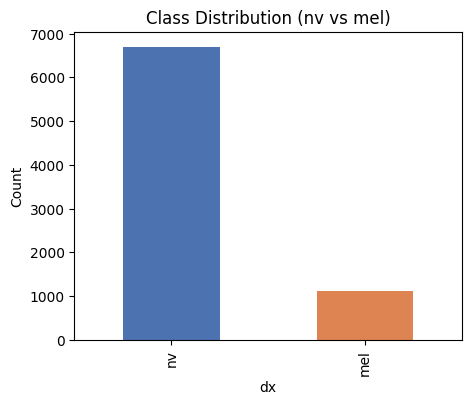

Imbalance ratio (nv:mel) = 6.02 : 1


In [36]:
plt.figure(figsize=(5,4))
df["dx"].value_counts().plot(kind="bar", color=["#4C72B0","#DD8452"])
plt.title("Class Distribution (nv vs mel)")
plt.ylabel("Count")
plt.savefig("class_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

imbalance_ratio = df["dx"].value_counts()["nv"] / df["dx"].value_counts()["mel"]
print(f"Imbalance ratio (nv:mel) = {imbalance_ratio:.2f} : 1")

In [38]:
def group_split(df, group_col="lesion_id", train_size=0.70, val_size=0.15, seed=SEED):
    # split 1: train vs (val+test)
    gss1 = GroupShuffleSplit(n_splits=1, train_size=train_size, random_state=seed)
    train_idx, rest_idx = next(gss1.split(df, groups=df[group_col]))
    train_df = df.iloc[train_idx].reset_index(drop=True)
    rest_df  = df.iloc[rest_idx].reset_index(drop=True)

    # split 2: val vs test (على الباقي، بنص بنص عشان val_size==test_size==15%)
    gss2 = GroupShuffleSplit(n_splits=1, train_size=0.5, random_state=seed)
    val_idx, test_idx = next(gss2.split(rest_df, groups=rest_df[group_col]))
    val_df  = rest_df.iloc[val_idx].reset_index(drop=True)
    test_df = rest_df.iloc[test_idx].reset_index(drop=True)
    return train_df, val_df, test_df

train_df, val_df, test_df = group_split(df)

print("Train:", train_df.shape, "| Val:", val_df.shape, "| Test:", test_df.shape)

# تأكيد إنه مفيش تداخل في lesion_id بين المجموعات
assert set(train_df.lesion_id) & set(val_df.lesion_id) == set()
assert set(train_df.lesion_id) & set(test_df.lesion_id) == set()
assert set(val_df.lesion_id) & set(test_df.lesion_id) == set()
print("✅ No lesion_id overlap between splits — no data leakage.")

for name, d in [("Train", train_df), ("Val", val_df), ("Test", test_df)]:
    print(name, d["dx"].value_counts().to_dict())

Train: (5465, 9) | Val: (1205, 9) | Test: (1148, 9)
✅ No lesion_id overlap between splits — no data leakage.
Train {'nv': 4686, 'mel': 779}
Val {'nv': 1015, 'mel': 190}
Test {'nv': 1004, 'mel': 144}


In [40]:
class SkinLesionDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        row = self.dataframe.iloc[idx]

        image_path = row["image_path"]
        label = row["label"]

        image = Image.open(image_path).convert("RGB")

        if self.transform:
            image = self.transform(image)

        label = torch.tensor(label, dtype=torch.long)

        return image, label

In [41]:
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

IMG_SIZE = 224

train_transform = T.Compose([
    T.Resize((IMG_SIZE, IMG_SIZE)),
    
    T.RandomHorizontalFlip(p=0.5),
    T.RandomVerticalFlip(p=0.5),
    T.RandomRotation(20),
    T.RandomResizedCrop(IMG_SIZE, scale=(0.85, 1.0)),
    T.ColorJitter(brightness=0.15, contrast=0.15),
    
    T.ToTensor(),
    T.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

eval_transform = T.Compose([
    T.Resize((IMG_SIZE, IMG_SIZE)),
    T.ToTensor(),
    T.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

print("✅ Transforms are ready!")

✅ Transforms are ready!


In [42]:
train_dataset = SkinLesionDataset(
    train_df,
    transform=train_transform
)

val_dataset = SkinLesionDataset(
    val_df,
    transform=eval_transform
)

test_dataset = SkinLesionDataset(
    test_df,
    transform=eval_transform
)

print("Train dataset:", len(train_dataset))
print("Validation dataset:", len(val_dataset))
print("Test dataset:", len(test_dataset))

Train dataset: 5465
Validation dataset: 1205
Test dataset: 1148


In [43]:
image, label = train_dataset[0]

print("Image shape:", image.shape)
print("Label:", label.item())
print("Image dtype:", image.dtype)

Image shape: torch.Size([3, 224, 224])
Label: 0
Image dtype: torch.float32


In [44]:
BATCH_SIZE = 16

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("DataLoaders created successfully!")

DataLoaders created successfully!


In [45]:
images, labels = next(iter(train_loader))

print("Batch images shape:", images.shape)
print("Batch labels shape:", labels.shape)
print("Labels:", labels[:10].tolist())

Batch images shape: torch.Size([16, 3, 224, 224])
Batch labels shape: torch.Size([16])
Labels: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


In [46]:
# Count samples in each class in the training set
class_counts = train_df["label"].value_counts().sort_index()

print("Class counts:")
print(class_counts)

# Calculate class weights
class_weights = 1.0 / torch.tensor(
    class_counts.values,
    dtype=torch.float32
)

# Normalize weights so their sum equals number of classes
class_weights = class_weights / class_weights.sum() * len(class_counts)

print("\nClass weights:")
print(class_weights)

Class counts:
label
0    4686
1     779
Name: count, dtype: int64

Class weights:
tensor([0.2851, 1.7149])


In [47]:
class_weights = class_weights.to(DEVICE)

print("Class weights device:", class_weights.device)

Class weights device: cpu


In [48]:
criterion = nn.CrossEntropyLoss(weight=class_weights)

print("✅ Weighted Cross-Entropy Loss is ready!")

✅ Weighted Cross-Entropy Loss is ready!


In [51]:
# Load pretrained ResNet-50
resnet = tvm.resnet50(weights=tvm.ResNet50_Weights.DEFAULT)

# Replace the final fully connected layer for binary classification
num_features = resnet.fc.in_features
resnet.fc = nn.Linear(num_features, 2)

# Move model to GPU
resnet = resnet.to(DEVICE)

print("ResNet-50 created successfully!")
print("Final layer:", resnet.fc)
print("Model device:", next(resnet.parameters()).device)

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 187MB/s] 


ResNet-50 created successfully!
Final layer: Linear(in_features=2048, out_features=2, bias=True)
Model device: cuda:0


In [52]:
print(resnet)

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 

In [54]:
print(resnet.fc)

Linear(in_features=2048, out_features=2, bias=True)


In [55]:
resnet.fc = nn.Linear(
    resnet.fc.in_features,
    2
)

print("New classifier:")
print(resnet.fc)

New classifier:
Linear(in_features=2048, out_features=2, bias=True)


In [56]:
# Freeze all ResNet layers
for param in resnet.parameters():
    param.requires_grad = False

# Keep the new classifier trainable
for param in resnet.fc.parameters():
    param.requires_grad = True

print("Trainable parameters:")
print(sum(p.numel() for p in resnet.parameters() if p.requires_grad))

print("\nTotal parameters:")
print(sum(p.numel() for p in resnet.parameters()))

Trainable parameters:
4098

Total parameters:
23512130


In [57]:
LEARNING_RATE = 1e-4

optimizer_resnet = optim.AdamW(
    filter(lambda p: p.requires_grad, resnet.parameters()),
    lr=LEARNING_RATE
)

print("Optimizer:", optimizer_resnet)
print("Learning rate:", LEARNING_RATE)

Optimizer: AdamW (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: True
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.0001
    maximize: False
    weight_decay: 0.01
)
Learning rate: 0.0001


In [60]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_accuracy = correct / total

    return epoch_loss, epoch_accuracy

In [61]:
@torch.no_grad()
def evaluate_model(model, loader, criterion, device):
    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        outputs = model(images)
        loss = criterion(outputs, labels)

        running_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_accuracy = correct / total

    return epoch_loss, epoch_accuracy

In [62]:
resnet = resnet.to(DEVICE)

print("ResNet moved to:", next(resnet.parameters()).device)

ResNet moved to: cuda:0


In [64]:
criterion = nn.CrossEntropyLoss(
    weight=class_weights.to(DEVICE)
)

print("Criterion:", criterion)
print("Class weights device:", criterion.weight.device)

Criterion: CrossEntropyLoss()
Class weights device: cuda:0


In [65]:
train_loss, train_acc = train_one_epoch(
    resnet,
    train_loader,
    criterion,
    optimizer_resnet,
    DEVICE
)

val_loss, val_acc = evaluate_model(
    resnet,
    val_loader,
    criterion,
    DEVICE
)

print(f"Train Loss: {train_loss:.4f}")
print(f"Train Accuracy: {train_acc:.4f}")
print(f"Val Loss: {val_loss:.4f}")
print(f"Val Accuracy: {val_acc:.4f}")

Train Loss: 0.5914
Train Accuracy: 0.8238
Val Loss: 0.4630
Val Accuracy: 0.7959


In [66]:
ؤ

Epoch [1/20] | Train Loss: 0.5106 | Train Acc: 0.8022 | Val Loss: 0.4943 | Val Acc: 0.7502
Epoch [2/20] | Train Loss: 0.4745 | Train Acc: 0.7958 | Val Loss: 0.4931 | Val Acc: 0.7436
Epoch [3/20] | Train Loss: 0.4550 | Train Acc: 0.7923 | Val Loss: 0.4775 | Val Acc: 0.7444
Epoch [4/20] | Train Loss: 0.4550 | Train Acc: 0.7894 | Val Loss: 0.4509 | Val Acc: 0.7560
Epoch [5/20] | Train Loss: 0.4364 | Train Acc: 0.7929 | Val Loss: 0.4773 | Val Acc: 0.7444
Epoch [6/20] | Train Loss: 0.4347 | Train Acc: 0.7923 | Val Loss: 0.4873 | Val Acc: 0.7427
Epoch [7/20] | Train Loss: 0.4289 | Train Acc: 0.7995 | Val Loss: 0.4525 | Val Acc: 0.7585
Epoch [8/20] | Train Loss: 0.4183 | Train Acc: 0.8009 | Val Loss: 0.4257 | Val Acc: 0.7759
Epoch [9/20] | Train Loss: 0.4168 | Train Acc: 0.8005 | Val Loss: 0.3857 | Val Acc: 0.7992
Epoch [10/20] | Train Loss: 0.4180 | Train Acc: 0.8064 | Val Loss: 0.3980 | Val Acc: 0.7917
Epoch [11/20] | Train Loss: 0.4037 | Train Acc: 0.8031 | Val Loss: 0.3929 | Val Acc: 0.79

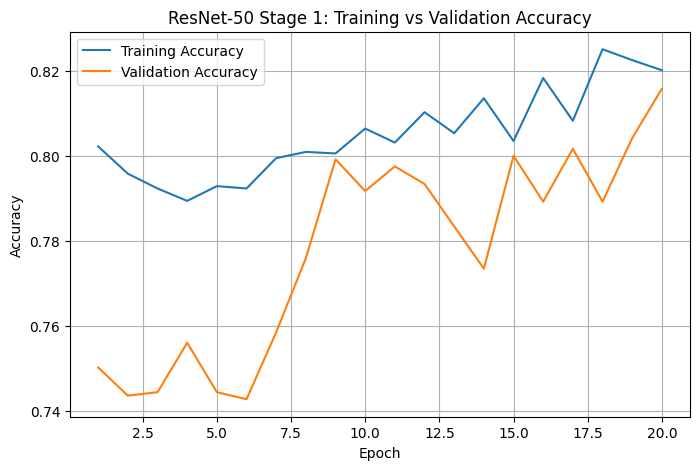

In [67]:
epochs = range(1, NUM_EPOCHS + 1)

plt.figure(figsize=(8, 5))
plt.plot(epochs, history_resnet_stage1["train_acc"], label="Training Accuracy")
plt.plot(epochs, history_resnet_stage1["val_acc"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("ResNet-50 Stage 1: Training vs Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()

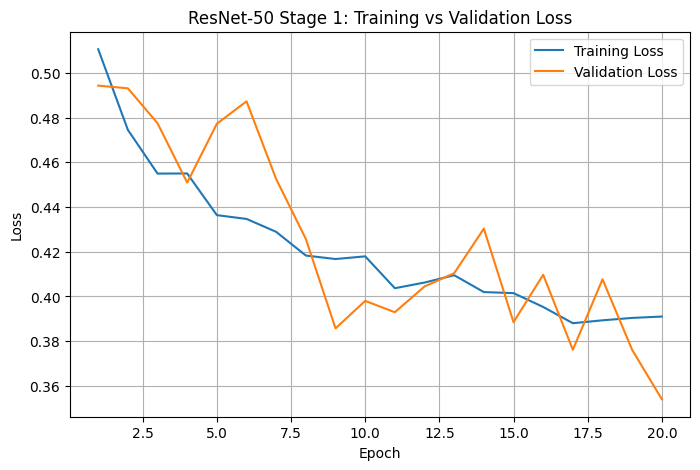

In [68]:
plt.figure(figsize=(8, 5))
plt.plot(epochs, history_resnet_stage1["train_loss"], label="Training Loss")
plt.plot(epochs, history_resnet_stage1["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("ResNet-50 Stage 1: Training vs Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

In [69]:
# Restore the best ResNet-50 from Stage 1
resnet.load_state_dict(best_resnet_stage1)

print("✅ Best Stage 1 ResNet restored.")

✅ Best Stage 1 ResNet restored.


In [70]:
# Freeze the entire network first
for param in resnet.parameters():
    param.requires_grad = False

# Unfreeze the deepest feature block
for param in resnet.layer4.parameters():
    param.requires_grad = True

# Keep the classifier trainable
for param in resnet.fc.parameters():
    param.requires_grad = True

trainable_params = sum(
    p.numel() for p in resnet.parameters()
    if p.requires_grad
)

total_params = sum(
    p.numel() for p in resnet.parameters()
)

print("Trainable parameters:", trainable_params)
print("Total parameters:", total_params)

Trainable parameters: 14968834
Total parameters: 23512130


In [71]:
FINETUNE_LR = 1e-5

optimizer_resnet_ft = optim.AdamW(
    filter(lambda p: p.requires_grad, resnet.parameters()),
    lr=FINETUNE_LR
)

print("Fine-tuning optimizer ready.")
print("Learning rate:", FINETUNE_LR)

Fine-tuning optimizer ready.
Learning rate: 1e-05


In [72]:
FT_EPOCHS = 10

history_resnet_ft = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": []
}

best_val_loss_ft = float("inf")
best_resnet_ft = None

start_time = time.time()

for epoch in range(FT_EPOCHS):

    train_loss, train_acc = train_one_epoch(
        resnet,
        train_loader,
        criterion,
        optimizer_resnet_ft,
        DEVICE
    )

    val_loss, val_acc = evaluate_model(
        resnet,
        val_loader,
        criterion,
        DEVICE
    )

    history_resnet_ft["train_loss"].append(train_loss)
    history_resnet_ft["val_loss"].append(val_loss)
    history_resnet_ft["train_acc"].append(train_acc)
    history_resnet_ft["val_acc"].append(val_acc)

    if val_loss < best_val_loss_ft:
        best_val_loss_ft = val_loss
        best_resnet_ft = copy.deepcopy(resnet.state_dict())

    print(
        f"Fine-tune Epoch [{epoch+1}/{FT_EPOCHS}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )

resnet_ft_time = time.time() - start_time

print(f"\nFine-tuning time: {resnet_ft_time/60:.2f} minutes")

Fine-tune Epoch [1/10] | Train Loss: 0.3787 | Train Acc: 0.8366 | Val Loss: 0.3664 | Val Acc: 0.8091
Fine-tune Epoch [2/10] | Train Loss: 0.3726 | Train Acc: 0.8342 | Val Loss: 0.3441 | Val Acc: 0.8274
Fine-tune Epoch [3/10] | Train Loss: 0.3593 | Train Acc: 0.8379 | Val Loss: 0.3753 | Val Acc: 0.8091
Fine-tune Epoch [4/10] | Train Loss: 0.3455 | Train Acc: 0.8472 | Val Loss: 0.3443 | Val Acc: 0.8290
Fine-tune Epoch [5/10] | Train Loss: 0.3166 | Train Acc: 0.8624 | Val Loss: 0.3445 | Val Acc: 0.8365
Fine-tune Epoch [6/10] | Train Loss: 0.3114 | Train Acc: 0.8662 | Val Loss: 0.3343 | Val Acc: 0.8473
Fine-tune Epoch [7/10] | Train Loss: 0.3228 | Train Acc: 0.8591 | Val Loss: 0.3180 | Val Acc: 0.8481
Fine-tune Epoch [8/10] | Train Loss: 0.2994 | Train Acc: 0.8734 | Val Loss: 0.3124 | Val Acc: 0.8456
Fine-tune Epoch [9/10] | Train Loss: 0.2984 | Train Acc: 0.8737 | Val Loss: 0.3124 | Val Acc: 0.8564
Fine-tune Epoch [10/10] | Train Loss: 0.2815 | Train Acc: 0.8876 | Val Loss: 0.3143 | Val A

In [73]:
# Restore the best fine-tuned ResNet-50
resnet.load_state_dict(best_resnet_ft)

print("✅ Best fine-tuned ResNet restored.")

✅ Best fine-tuned ResNet restored.


In [76]:
@torch.no_grad()
def get_predictions(model, loader, device):
    model.eval()

    all_labels = []
    all_preds = []
    all_probs = []

    for images, labels in loader:
        images = images.to(device, non_blocking=True)

        outputs = model(images)

        # Convert logits to probabilities
        probabilities = torch.softmax(outputs, dim=1)

        # Predicted class
        predictions = torch.argmax(probabilities, dim=1)

        # Probability of class 1 = Melanoma
        melanoma_probs = probabilities[:, 1]

        all_labels.extend(labels.numpy())
        all_preds.extend(predictions.cpu().numpy())
        all_probs.extend(melanoma_probs.cpu().numpy())

    return (
        np.array(all_labels),
        np.array(all_preds),
        np.array(all_probs)
    )

In [77]:
y_true_resnet, y_pred_resnet, y_prob_resnet = get_predictions(
    resnet,
    test_loader,
    DEVICE
)

print("Number of test samples:", len(y_true_resnet))
print("True labels shape:", y_true_resnet.shape)
print("Predicted labels shape:", y_pred_resnet.shape)
print("Probabilities shape:", y_prob_resnet.shape)

Number of test samples: 1148
True labels shape: (1148,)
Predicted labels shape: (1148,)
Probabilities shape: (1148,)


In [78]:
accuracy_resnet = accuracy_score(
    y_true_resnet,
    y_pred_resnet
)

precision_resnet = precision_score(
    y_true_resnet,
    y_pred_resnet,
    zero_division=0
)

recall_resnet = recall_score(
    y_true_resnet,
    y_pred_resnet,
    zero_division=0
)

f1_resnet = f1_score(
    y_true_resnet,
    y_pred_resnet,
    zero_division=0
)

roc_auc_resnet = roc_auc_score(
    y_true_resnet,
    y_prob_resnet
)

cm_resnet = confusion_matrix(
    y_true_resnet,
    y_pred_resnet
)

print(f"Accuracy    : {accuracy_resnet:.4f}")
print(f"Precision   : {precision_resnet:.4f}")
print(f"Sensitivity : {recall_resnet:.4f}")
print(f"F1 Score    : {f1_resnet:.4f}")
print(f"ROC-AUC     : {roc_auc_resnet:.4f}")

Accuracy    : 0.8841
Precision   : 0.5258
Sensitivity : 0.7778
F1 Score    : 0.6275
ROC-AUC     : 0.9253


In [79]:
tn, fp, fn, tp = cm_resnet.ravel()

specificity_resnet = tn / (tn + fp)

print(f"Specificity : {specificity_resnet:.4f}")

Specificity : 0.8994


In [80]:
print("ResNet-50 Confusion Matrix:")
print(cm_resnet)

print("\nTN:", tn)
print("FP:", fp)
print("FN:", fn)
print("TP:", tp)

ResNet-50 Confusion Matrix:
[[903 101]
 [ 32 112]]

TN: 903
FP: 101
FN: 32
TP: 112


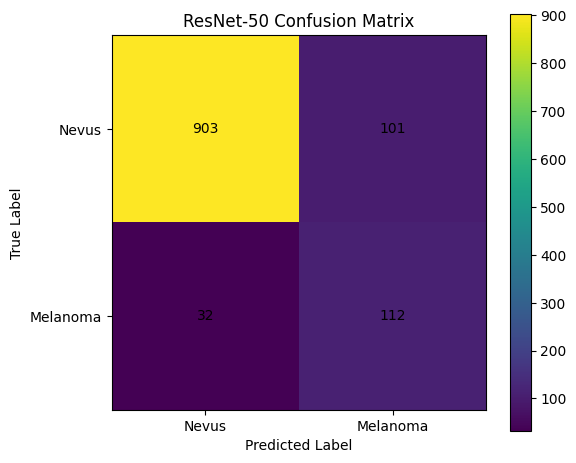

In [81]:
plt.figure(figsize=(6, 5))

plt.imshow(cm_resnet, interpolation="nearest")
plt.title("ResNet-50 Confusion Matrix")
plt.colorbar()

plt.xticks([0, 1], ["Nevus", "Melanoma"])
plt.yticks([0, 1], ["Nevus", "Melanoma"])

plt.xlabel("Predicted Label")
plt.ylabel("True Label")

for i in range(2):
    for j in range(2):
        plt.text(
            j,
            i,
            cm_resnet[i, j],
            ha="center",
            va="center"
        )

plt.tight_layout()
plt.show()

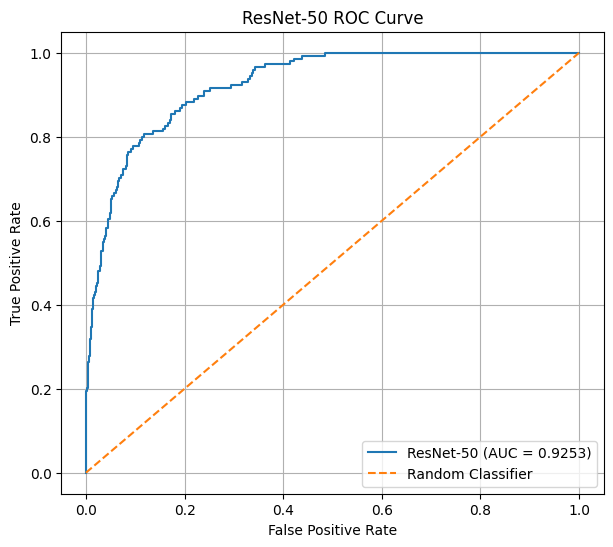

In [82]:
fpr_resnet, tpr_resnet, thresholds_resnet = roc_curve(
    y_true_resnet,
    y_prob_resnet
)

plt.figure(figsize=(7, 6))

plt.plot(
    fpr_resnet,
    tpr_resnet,
    label=f"ResNet-50 (AUC = {roc_auc_resnet:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ResNet-50 ROC Curve")
plt.legend()
plt.grid(True)
plt.show()

## Step 6 — EfficientNet-B0 Transfer Learning

In [83]:
efficientnet = tvm.efficientnet_b0(
    weights=tvm.EfficientNet_B0_Weights.DEFAULT
)

print("✅ EfficientNet-B0 loaded successfully!")

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 146MB/s]

✅ EfficientNet-B0 loaded successfully!


In [84]:
print(efficientnet.classifier)

Sequential(
  (0): Dropout(p=0.2, inplace=True)
  (1): Linear(in_features=1280, out_features=1000, bias=True)
)


In [85]:
efficientnet.classifier[1] = nn.Linear(
    efficientnet.classifier[1].in_features,
    2
)

print("New classifier:")
print(efficientnet.classifier)

New classifier:
Sequential(
  (0): Dropout(p=0.2, inplace=True)
  (1): Linear(in_features=1280, out_features=2, bias=True)
)


In [86]:
# Freeze the EfficientNet backbone
for param in efficientnet.parameters():
    param.requires_grad = False

# Keep the new classifier trainable
for param in efficientnet.classifier.parameters():
    param.requires_grad = True

trainable_params_eff = sum(
    p.numel()
    for p in efficientnet.parameters()
    if p.requires_grad
)

total_params_eff = sum(
    p.numel()
    for p in efficientnet.parameters()
)

print("Trainable parameters:", trainable_params_eff)
print("Total parameters:", total_params_eff)

Trainable parameters: 2562
Total parameters: 4010110


In [87]:
efficientnet = efficientnet.to(DEVICE)

print("EfficientNet device:", next(efficientnet.parameters()).device)

EfficientNet device: cuda:0


In [88]:
LEARNING_RATE = 1e-4

optimizer_eff = optim.AdamW(
    filter(lambda p: p.requires_grad, efficientnet.parameters()),
    lr=LEARNING_RATE
)

print("Optimizer:", optimizer_eff)
print("Learning rate:", LEARNING_RATE)

Optimizer: AdamW (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: True
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.0001
    maximize: False
    weight_decay: 0.01
)
Learning rate: 0.0001


In [89]:
train_loss, train_acc = train_one_epoch(
    efficientnet,
    train_loader,
    criterion,
    optimizer_eff,
    DEVICE
)

val_loss, val_acc = evaluate_model(
    efficientnet,
    val_loader,
    criterion,
    DEVICE
)

print(f"Train Loss: {train_loss:.4f}")
print(f"Train Accuracy: {train_acc:.4f}")
print(f"Val Loss: {val_loss:.4f}")
print(f"Val Accuracy: {val_acc:.4f}")

Train Loss: 0.6004
Train Accuracy: 0.7233
Val Loss: 0.5366
Val Accuracy: 0.7228


In [90]:
efficientnet = tvm.efficientnet_b0(
    weights=tvm.EfficientNet_B0_Weights.DEFAULT
)

efficientnet.classifier[1] = nn.Linear(
    efficientnet.classifier[1].in_features,
    2
)

# Freeze backbone
for param in efficientnet.parameters():
    param.requires_grad = False

# Train classifier only
for param in efficientnet.classifier.parameters():
    param.requires_grad = True

efficientnet = efficientnet.to(DEVICE)

# New optimizer
optimizer_eff = optim.AdamW(
    filter(lambda p: p.requires_grad, efficientnet.parameters()),
    lr=1e-4
)

print("✅ EfficientNet-B0 reset and ready for Stage 1")

✅ EfficientNet-B0 reset and ready for Stage 1


In [91]:
NUM_EPOCHS_EFF = 20

history_eff_stage1 = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": []
}

best_val_loss_eff = float("inf")
best_eff_stage1 = None

start_time = time.time()

for epoch in range(NUM_EPOCHS_EFF):

    train_loss, train_acc = train_one_epoch(
        efficientnet,
        train_loader,
        criterion,
        optimizer_eff,
        DEVICE
    )

    val_loss, val_acc = evaluate_model(
        efficientnet,
        val_loader,
        criterion,
        DEVICE
    )

    history_eff_stage1["train_loss"].append(train_loss)
    history_eff_stage1["val_loss"].append(val_loss)
    history_eff_stage1["train_acc"].append(train_acc)
    history_eff_stage1["val_acc"].append(val_acc)

    if val_loss < best_val_loss_eff:
        best_val_loss_eff = val_loss
        best_eff_stage1 = copy.deepcopy(efficientnet.state_dict())

    print(
        f"EfficientNet Stage 1 "
        f"Epoch [{epoch+1}/{NUM_EPOCHS_EFF}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )

eff_stage1_time = time.time() - start_time

print(f"\nEfficientNet Stage 1 training time: {eff_stage1_time/60:.2f} minutes")

EfficientNet Stage 1 Epoch [1/20] | Train Loss: 0.5166 | Train Acc: 0.7561 | Val Loss: 0.4988 | Val Acc: 0.7303
EfficientNet Stage 1 Epoch [2/20] | Train Loss: 0.4708 | Train Acc: 0.7760 | Val Loss: 0.5045 | Val Acc: 0.7253
EfficientNet Stage 1 Epoch [3/20] | Train Loss: 0.4758 | Train Acc: 0.7705 | Val Loss: 0.5111 | Val Acc: 0.7195
EfficientNet Stage 1 Epoch [4/20] | Train Loss: 0.4571 | Train Acc: 0.7795 | Val Loss: 0.5008 | Val Acc: 0.7336
EfficientNet Stage 1 Epoch [5/20] | Train Loss: 0.4563 | Train Acc: 0.7802 | Val Loss: 0.4711 | Val Acc: 0.7535
EfficientNet Stage 1 Epoch [6/20] | Train Loss: 0.4466 | Train Acc: 0.7850 | Val Loss: 0.4598 | Val Acc: 0.7635
EfficientNet Stage 1 Epoch [7/20] | Train Loss: 0.4607 | Train Acc: 0.7843 | Val Loss: 0.4386 | Val Acc: 0.7685
EfficientNet Stage 1 Epoch [8/20] | Train Loss: 0.4489 | Train Acc: 0.7881 | Val Loss: 0.4673 | Val Acc: 0.7577
EfficientNet Stage 1 Epoch [9/20] | Train Loss: 0.4384 | Train Acc: 0.7890 | Val Loss: 0.5013 | Val Acc:

In [96]:
for param in efficientnet.parameters():
    param.requires_grad = False

In [100]:
# Unfreeze the last feature block
for param in efficientnet.features[-1].parameters():
    param.requires_grad = True

# Keep classifier trainable
for param in efficientnet.classifier.parameters():
    param.requires_grad = True

In [101]:
trainable_params_eff_ft = sum(
    p.numel()
    for p in efficientnet.parameters()
    if p.requires_grad
)

total_params_eff = sum(
    p.numel()
    for p in efficientnet.parameters()
)

print("Trainable parameters:", trainable_params_eff_ft)
print("Total parameters:", total_params_eff)

Trainable parameters: 414722
Total parameters: 4010110


In [102]:
FINETUNE_LR_EFF = 1e-5

optimizer_eff_ft = optim.AdamW(
    filter(lambda p: p.requires_grad, efficientnet.parameters()),
    lr=FINETUNE_LR_EFF
)

print("Fine-tuning optimizer ready.")
print("Learning rate:", FINETUNE_LR_EFF)

Fine-tuning optimizer ready.
Learning rate: 1e-05


In [104]:
FT_EPOCHS_EFF = 10

history_eff_ft = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": []
}

best_val_loss_eff_ft = float("inf")
best_eff_ft = None

start_time = time.time()

for epoch in range(FT_EPOCHS_EFF):

    train_loss, train_acc = train_one_epoch(
        efficientnet,
        train_loader,
        criterion,
        optimizer_eff_ft,
        DEVICE
    )

    val_loss, val_acc = evaluate_model(
        efficientnet,
        val_loader,
        criterion,
        DEVICE
    )

    history_eff_ft["train_loss"].append(train_loss)
    history_eff_ft["val_loss"].append(val_loss)
    history_eff_ft["train_acc"].append(train_acc)
    history_eff_ft["val_acc"].append(val_acc)

    if val_loss < best_val_loss_eff_ft:
        best_val_loss_eff_ft = val_loss
        best_eff_ft = copy.deepcopy(efficientnet.state_dict())

    print(
        f"EfficientNet Fine-tune "
        f"Epoch [{epoch+1}/{FT_EPOCHS_EFF}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )

eff_ft_time = time.time() - start_time

print(f"\nEfficientNet Fine-tuning time: {eff_ft_time/60:.2f} minutes")

EfficientNet Fine-tune Epoch [1/10] | Train Loss: 0.4193 | Train Acc: 0.8090 | Val Loss: 0.4147 | Val Acc: 0.7842
EfficientNet Fine-tune Epoch [2/10] | Train Loss: 0.4098 | Train Acc: 0.8093 | Val Loss: 0.4148 | Val Acc: 0.7801
EfficientNet Fine-tune Epoch [3/10] | Train Loss: 0.4174 | Train Acc: 0.8117 | Val Loss: 0.4053 | Val Acc: 0.7851
EfficientNet Fine-tune Epoch [4/10] | Train Loss: 0.4154 | Train Acc: 0.8128 | Val Loss: 0.4238 | Val Acc: 0.7826
EfficientNet Fine-tune Epoch [5/10] | Train Loss: 0.4114 | Train Acc: 0.8071 | Val Loss: 0.4183 | Val Acc: 0.7867
EfficientNet Fine-tune Epoch [6/10] | Train Loss: 0.4066 | Train Acc: 0.8108 | Val Loss: 0.4185 | Val Acc: 0.7826
EfficientNet Fine-tune Epoch [7/10] | Train Loss: 0.4051 | Train Acc: 0.8095 | Val Loss: 0.4250 | Val Acc: 0.7834
EfficientNet Fine-tune Epoch [8/10] | Train Loss: 0.4077 | Train Acc: 0.8075 | Val Loss: 0.3722 | Val Acc: 0.8075
EfficientNet Fine-tune Epoch [9/10] | Train Loss: 0.4090 | Train Acc: 0.8093 | Val Loss:

In [105]:
# Restore the best EfficientNet Stage 1 model
efficientnet.load_state_dict(best_eff_stage1)

print("✅ Best EfficientNet Stage 1 model restored.")

✅ Best EfficientNet Stage 1 model restored.


In [107]:
# Restore the best EfficientNet fine-tuned model
efficientnet.load_state_dict(best_eff_ft)

print("✅ Best EfficientNet fine-tuned model restored.")

✅ Best EfficientNet fine-tuned model restored.


In [106]:
y_true_eff, y_pred_eff, y_prob_eff = get_predictions(
    efficientnet,
    test_loader,
    DEVICE
)

print("Number of test samples:", len(y_true_eff))
print("True labels shape:", y_true_eff.shape)
print("Predicted labels shape:", y_pred_eff.shape)
print("Probabilities shape:", y_prob_eff.shape)

Number of test samples: 1148
True labels shape: (1148,)
Predicted labels shape: (1148,)
Probabilities shape: (1148,)


In [108]:
accuracy_eff = accuracy_score(
    y_true_eff,
    y_pred_eff
)

precision_eff = precision_score(
    y_true_eff,
    y_pred_eff,
    zero_division=0
)

recall_eff = recall_score(
    y_true_eff,
    y_pred_eff,
    zero_division=0
)

f1_eff = f1_score(
    y_true_eff,
    y_pred_eff,
    zero_division=0
)

roc_auc_eff = roc_auc_score(
    y_true_eff,
    y_prob_eff
)

cm_eff = confusion_matrix(
    y_true_eff,
    y_pred_eff
)

print(f"Accuracy    : {accuracy_eff:.4f}")
print(f"Precision   : {precision_eff:.4f}")
print(f"Sensitivity : {recall_eff:.4f}")
print(f"F1 Score    : {f1_eff:.4f}")
print(f"ROC-AUC     : {roc_auc_eff:.4f}")

Accuracy    : 0.7953
Precision   : 0.3600
Sensitivity : 0.8125
F1 Score    : 0.4989
ROC-AUC     : 0.8917


In [109]:
tn_eff, fp_eff, fn_eff, tp_eff = cm_eff.ravel()

specificity_eff = tn_eff / (tn_eff + fp_eff)

print("EfficientNet-B0 Confusion Matrix:")
print(cm_eff)

print("\nTN:", tn_eff)
print("FP:", fp_eff)
print("FN:", fn_eff)
print("TP:", tp_eff)

print(f"Specificity : {specificity_eff:.4f}")

EfficientNet-B0 Confusion Matrix:
[[796 208]
 [ 27 117]]

TN: 796
FP: 208
FN: 27
TP: 117
Specificity : 0.7928


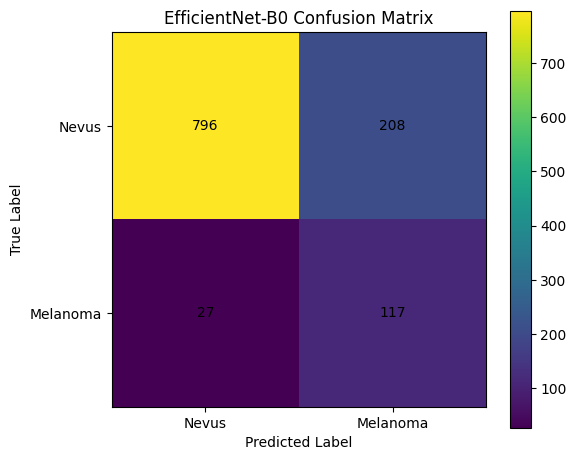

In [110]:
plt.figure(figsize=(6, 5))

plt.imshow(cm_eff, interpolation="nearest")
plt.title("EfficientNet-B0 Confusion Matrix")
plt.colorbar()

plt.xticks([0, 1], ["Nevus", "Melanoma"])
plt.yticks([0, 1], ["Nevus", "Melanoma"])

plt.xlabel("Predicted Label")
plt.ylabel("True Label")

for i in range(2):
    for j in range(2):
        plt.text(
            j,
            i,
            cm_eff[i, j],
            ha="center",
            va="center"
        )

plt.tight_layout()
plt.show()

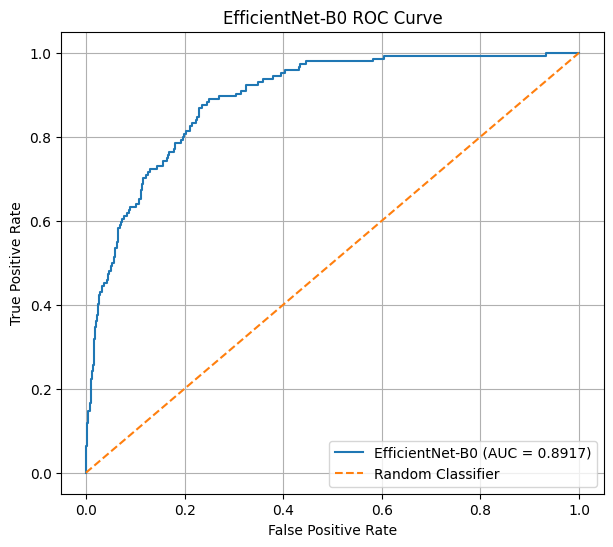

In [111]:
fpr_eff, tpr_eff, thresholds_eff = roc_curve(
    y_true_eff,
    y_prob_eff
)

plt.figure(figsize=(7, 6))

plt.plot(
    fpr_eff,
    tpr_eff,
    label=f"EfficientNet-B0 (AUC = {roc_auc_eff:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("EfficientNet-B0 ROC Curve")
plt.legend()
plt.grid(True)
plt.show()

## ResNet-50 vs EfficientNet-B0 Comparison

In [113]:
comparison_df = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Sensitivity",
        "Specificity",
        "F1 Score",
        "ROC-AUC",
        "Total Parameters",
        "Stage 1 Training Time (min)",
        "Stage 2 Training Time (min)"
    ],

    "ResNet-50": [
        accuracy_resnet,
        precision_resnet,
        recall_resnet,
        specificity_resnet,
        f1_resnet,
        roc_auc_resnet,
        23512130,
        14.15,   # current recorded Stage 1 time
        resnet_ft_time / 60
    ],

    "EfficientNet-B0": [
        accuracy_eff,
        precision_eff,
        recall_eff,
        specificity_eff,
        f1_eff,
        roc_auc_eff,
        4010110,
        eff_stage1_time / 60,
        eff_ft_time / 60
    ]
})

comparison_df

,Metric,ResNet-50,EfficientNet-B0
0,Accuracy,8.841463e-01,7.952962e-01
1,Precision,5.258216e-01,3.600000e-01
2,Sensitivity,7.777778e-01,8.125000e-01
3,Specificity,8.994024e-01,7.928287e-01
4,F1 Score,6.274510e-01,4.989339e-01
5,ROC-AUC,9.252988e-01,8.917317e-01
6,Total Parameters,2.351213e+07,4.010110e+06
7,Stage 1 Training Time (min),1.415000e+01,1.482506e+01
8,Stage 2 Training Time (min),7.788550e+00,7.466715e+00


In [114]:
# Restore the best ResNet-50 fine-tuned model
resnet.load_state_dict(best_resnet_ft)
resnet = resnet.to(DEVICE)

# Get ResNet predictions on the test set
y_true_resnet, y_pred_resnet, y_prob_resnet = get_predictions(
    resnet,
    test_loader,
    DEVICE
)

print("ResNet test samples:", len(y_true_resnet))
print("True labels shape:", y_true_resnet.shape)
print("Predicted labels shape:", y_pred_resnet.shape)
print("Probabilities shape:", y_prob_resnet.shape)

ResNet test samples: 1148
True labels shape: (1148,)
Predicted labels shape: (1148,)
Probabilities shape: (1148,)


In [125]:
# Measure ResNet-50 inference time
resnet_total_time, resnet_avg_time, resnet_images_per_sec = measure_inference_time(
    resnet,
    test_loader,
    DEVICE
)

print("ResNet-50 Inference:")
print(f"Total time: {resnet_total_time:.4f} seconds")
print(f"Average time per image: {resnet_avg_time:.6f} seconds")
print(f"Images per second: {resnet_images_per_sec:.2f}")

ResNet-50 Inference:
Total time: 5.9906 seconds
Average time per image: 0.005218 seconds
Images per second: 191.63


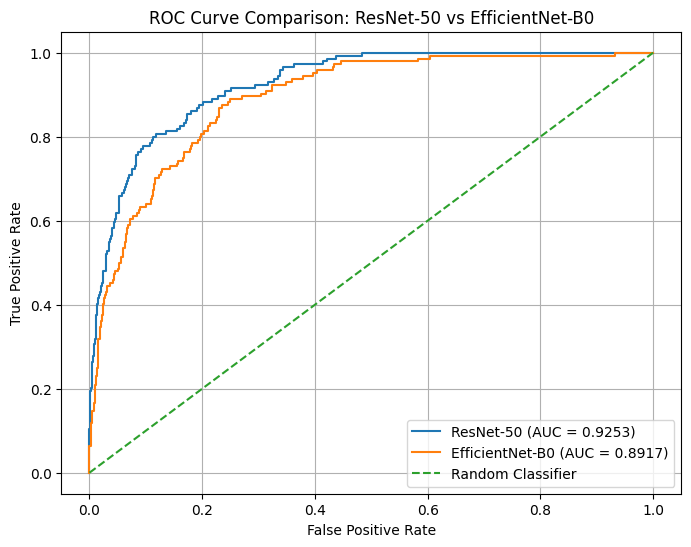

ResNet-50 ROC-AUC: 0.9253
EfficientNet-B0 ROC-AUC: 0.8917


In [115]:
# Calculate ROC curves
fpr_resnet, tpr_resnet, _ = roc_curve(
    y_true_resnet,
    y_prob_resnet
)

fpr_eff, tpr_eff, _ = roc_curve(
    y_true_eff,
    y_prob_eff
)

# Calculate AUC
roc_auc_resnet = roc_auc_score(
    y_true_resnet,
    y_prob_resnet
)

roc_auc_eff = roc_auc_score(
    y_true_eff,
    y_prob_eff
)

# Plot
plt.figure(figsize=(8, 6))

plt.plot(
    fpr_resnet,
    tpr_resnet,
    label=f"ResNet-50 (AUC = {roc_auc_resnet:.4f})"
)

plt.plot(
    fpr_eff,
    tpr_eff,
    label=f"EfficientNet-B0 (AUC = {roc_auc_eff:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison: ResNet-50 vs EfficientNet-B0")
plt.legend()
plt.grid(True)
plt.show()

print(f"ResNet-50 ROC-AUC: {roc_auc_resnet:.4f}")
print(f"EfficientNet-B0 ROC-AUC: {roc_auc_eff:.4f}")

## Inference Time Comparison

In [124]:
def measure_inference_time(model, loader, device, warmup_batches=5):
    model.eval()

    # Warm-up GPU
    with torch.no_grad():
        for i, (images, labels) in enumerate(loader):
            images = images.to(device)

            _ = model(images)

            if device.type == "cuda":
                torch.cuda.synchronize()

            if i + 1 >= warmup_batches:
                break

    # Actual timing
    total_images = 0

    if device.type == "cuda":
        torch.cuda.synchronize()

    start_time = time.time()

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)

            _ = model(images)

            total_images += images.size(0)

    if device.type == "cuda":
        torch.cuda.synchronize()

    total_time = time.time() - start_time

    avg_time_per_image = total_time / total_images
    images_per_second = total_images / total_time

    return total_time, avg_time_per_image, images_per_second

In [128]:
# Measure EfficientNet-B0 inference time
efficientnet_total_time, efficientnet_avg_time, efficientnet_images_per_sec = measure_inference_time(
    efficientnet,
    test_loader,
    DEVICE
)

print("EfficientNet-B0 Inference:")
print(f"Total time: {efficientnet_total_time:.4f} seconds")
print(f"Average time per image: {efficientnet_avg_time:.6f} seconds")
print(f"Images per second: {efficientnet_images_per_sec:.2f}")

EfficientNet-B0 Inference:
Total time: 6.0026 seconds
Average time per image: 0.005229 seconds
Images per second: 191.25


In [127]:
resnet.load_state_dict(best_resnet_ft)
resnet = resnet.to(DEVICE)

In [121]:
efficientnet.load_state_dict(best_eff_stage1)
efficientnet = efficientnet.to(DEVICE)

In [129]:
print("ResNet device:", next(resnet.parameters()).device)
print("EfficientNet device:", next(efficientnet.parameters()).device)

ResNet device: cuda:0
EfficientNet device: cuda:0


In [131]:
resnet_total_time, resnet_avg_time, resnet_fps = measure_inference_time(
    resnet,
    test_loader,
    DEVICE
)

print("ResNet-50 Inference")
print(f"Total time: {resnet_total_time:.4f} seconds")
print(f"Average time per image: {resnet_avg_time*1000:.4f} ms")
print(f"Images per second: {resnet_fps:.2f}")

ResNet-50 Inference
Total time: 6.0777 seconds
Average time per image: 5.2942 ms
Images per second: 188.89


## Training Curves

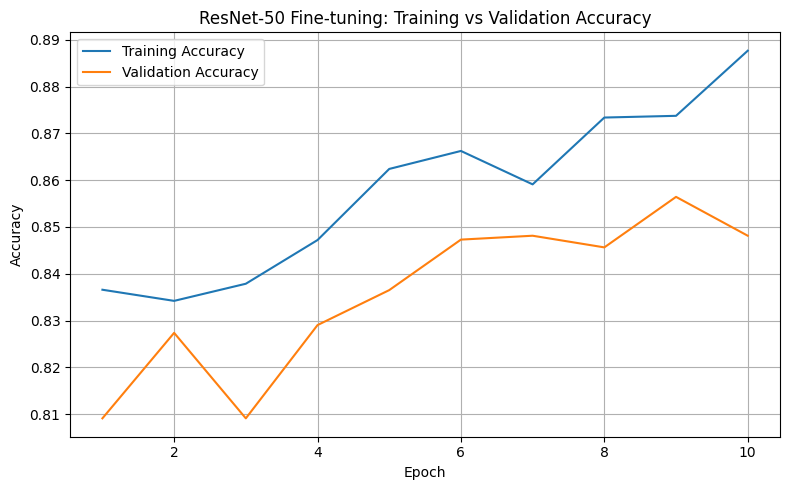

In [148]:
epochs_resnet_ft = range(1, len(history_resnet_ft["train_acc"]) + 1)

plt.figure(figsize=(8, 5))

plt.plot(
    epochs_resnet_ft,
    history_resnet_ft["train_acc"],
    label="Training Accuracy"
)

plt.plot(
    epochs_resnet_ft,
    history_resnet_ft["val_acc"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("ResNet-50 Fine-tuning: Training vs Validation Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

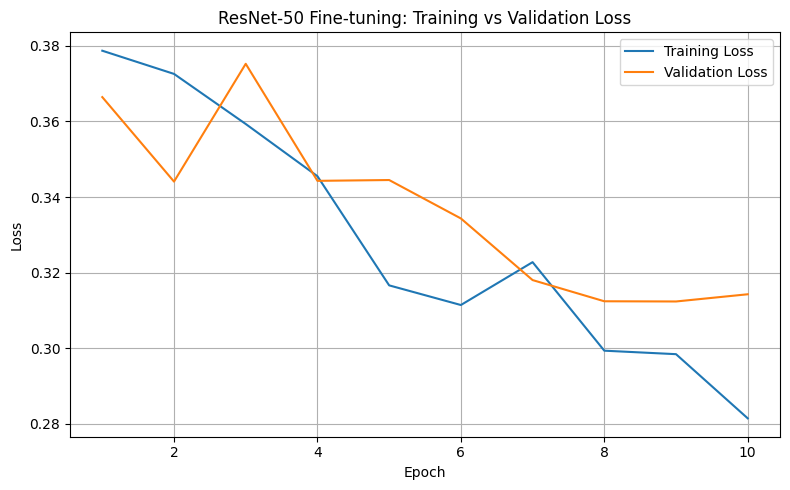

In [149]:
epochs_resnet_ft = range(1, len(history_resnet_ft["train_loss"]) + 1)

plt.figure(figsize=(8, 5))

plt.plot(
    epochs_resnet_ft,
    history_resnet_ft["train_loss"],
    label="Training Loss"
)

plt.plot(
    epochs_resnet_ft,
    history_resnet_ft["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("ResNet-50 Fine-tuning: Training vs Validation Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

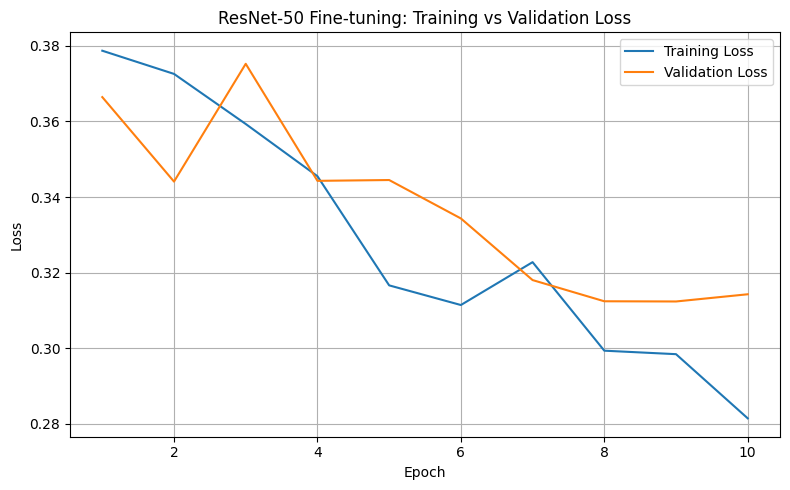

In [150]:
epochs_resnet_ft = range(1, len(history_resnet_ft["train_loss"]) + 1)

plt.figure(figsize=(8, 5))

plt.plot(
    epochs_resnet_ft,
    history_resnet_ft["train_loss"],
    label="Training Loss"
)

plt.plot(
    epochs_resnet_ft,
    history_resnet_ft["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("ResNet-50 Fine-tuning: Training vs Validation Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

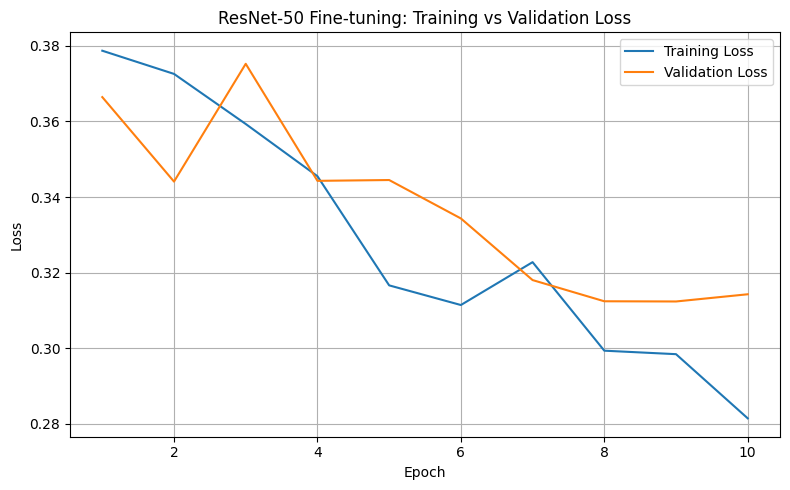

In [151]:
epochs_resnet_ft = range(1, len(history_resnet_ft["train_loss"]) + 1)

plt.figure(figsize=(8, 5))

plt.plot(
    epochs_resnet_ft,
    history_resnet_ft["train_loss"],
    label="Training Loss"
)

plt.plot(
    epochs_resnet_ft,
    history_resnet_ft["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("ResNet-50 Fine-tuning: Training vs Validation Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()



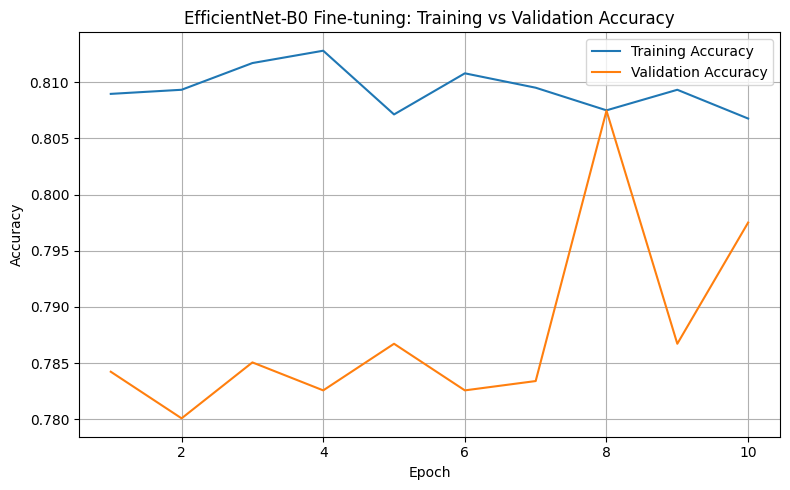

In [152]:
epochs_eff_ft = range(1, len(history_eff_ft["train_acc"]) + 1)

plt.figure(figsize=(8, 5))

plt.plot(
    epochs_eff_ft,
    history_eff_ft["train_acc"],
    label="Training Accuracy"
)

plt.plot(
    epochs_eff_ft,
    history_eff_ft["val_acc"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("EfficientNet-B0 Fine-tuning: Training vs Validation Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

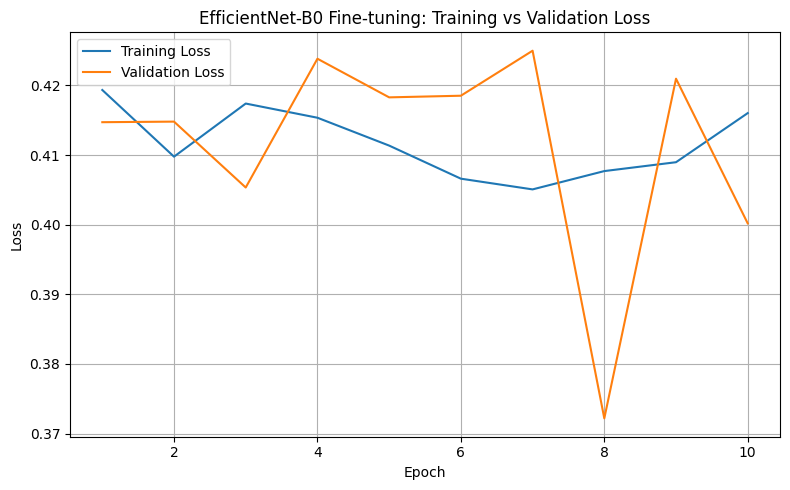

In [153]:
epochs_eff_ft = range(1, len(history_eff_ft["train_loss"]) + 1)

plt.figure(figsize=(8, 5))

plt.plot(
    epochs_eff_ft,
    history_eff_ft["train_loss"],
    label="Training Loss"
)

plt.plot(
    epochs_eff_ft,
    history_eff_ft["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("EfficientNet-B0 Fine-tuning: Training vs Validation Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [133]:
inference_df = pd.DataFrame({
    "Metric": [
        "Total Inference Time (s)",
        "Average Time per Image (ms)",
        "Images per Second"
    ],

    "ResNet-50": [
        resnet_total_time,
        resnet_avg_time * 1000,
        resnet_fps
    ],

    "EfficientNet-B0": [
        eff_total_time,
        eff_avg_time * 1000,
        eff_fps
    ]
})

inference_df

,Metric,ResNet-50,EfficientNet-B0
0,Total Inference Time (s),6.077731,5.957489
1,Average Time per Image (ms),5.294191,5.189451
2,Images per Second,188.886269,192.698619


In [132]:
eff_total_time, eff_avg_time, eff_fps = measure_inference_time(
    efficientnet,
    test_loader,
    DEVICE
)

print("\nEfficientNet-B0 Inference")
print(f"Total time: {eff_total_time:.4f} seconds")
print(f"Average time per image: {eff_avg_time*1000:.4f} ms")
print(f"Images per second: {eff_fps:.2f}")


EfficientNet-B0 Inference
Total time: 5.9575 seconds
Average time per image: 5.1895 ms
Images per second: 192.70


In [155]:
import io

def get_model_size_mb(model):
    buffer = io.BytesIO()
    torch.save(model.state_dict(), buffer)
    return buffer.getbuffer().nbytes / (1024 ** 2)

resnet_size_mb = get_model_size_mb(resnet)
efficientnet_size_mb = get_model_size_mb(efficientnet)

print(f"ResNet-50 Model Size: {resnet_size_mb:.2f} MB")
print(f"EfficientNet-B0 Model Size: {efficientnet_size_mb:.2f} MB")

ResNet-50 Model Size: 89.99 MB
EfficientNet-B0 Model Size: 15.58 MB


In [154]:
# ==========================================
# Computational Comparison: ResNet-50 vs EfficientNet-B0
# ==========================================

import io

# Function to count parameters
def count_parameters(model):
    total_params = sum(p.numel() for p in model.parameters())
    
    trainable_params = sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    )
    
    return trainable_params, total_params


# Function to calculate actual model size
def get_model_size_mb(model):
    buffer = io.BytesIO()
    torch.save(model.state_dict(), buffer)
    size_mb = buffer.getbuffer().nbytes / (1024 ** 2)
    return size_mb


# ResNet-50 parameters
resnet_trainable, resnet_total = count_parameters(resnet)
resnet_size_mb = get_model_size_mb(resnet)


# EfficientNet-B0 parameters
eff_trainable, eff_total = count_parameters(efficientnet)
eff_size_mb = get_model_size_mb(efficientnet)


# Create comparison table
computational_df = pd.DataFrame({
    "Metric": [
        "Trainable Parameters",
        "Total Parameters",
        "Model Size (MB)",
        "Average Inference Time (ms/image)",
        "Images per Second"
    ],
    
    "ResNet-50": [
        resnet_trainable,
        resnet_total,
        resnet_size_mb,
        resnet_avg_time * 1000,
        resnet_fps
    ],
    
    "EfficientNet-B0": [
        eff_trainable,
        eff_total,
        eff_size_mb,
        eff_avg_time * 1000,
        eff_fps
    ]
})


computational_df

,Metric,ResNet-50,EfficientNet-B0
0,Trainable Parameters,1.496883e+07,4.147220e+05
1,Total Parameters,2.351213e+07,4.010110e+06
2,Model Size (MB),8.999444e+01,1.558147e+01
3,Average Inference Time (ms/image),5.294191e+00,5.189451e+00
4,Images per Second,1.888863e+02,1.926986e+02


## Error Analysis

In [134]:
# Create error masks for ResNet-50
resnet_fp_mask = (y_true_resnet == 0) & (y_pred_resnet == 1)
resnet_fn_mask = (y_true_resnet == 1) & (y_pred_resnet == 0)

# Create error masks for EfficientNet-B0
eff_fp_mask = (y_true_eff == 0) & (y_pred_eff == 1)
eff_fn_mask = (y_true_eff == 1) & (y_pred_eff == 0)

print("ResNet-50:")
print("False Positives:", resnet_fp_mask.sum())
print("False Negatives:", resnet_fn_mask.sum())

print("\nEfficientNet-B0:")
print("False Positives:", eff_fp_mask.sum())
print("False Negatives:", eff_fn_mask.sum())

ResNet-50:
False Positives: 101
False Negatives: 32

EfficientNet-B0:
False Positives: 208
False Negatives: 27


In [136]:
def show_errors(
    df,
    mask,
    y_true,
    y_pred,
    y_prob,
    title,
    n=5
):
    indices = np.where(mask)[0][:n]

    plt.figure(figsize=(15, 3))

    for plot_idx, idx in enumerate(indices):

        image_path = df.iloc[idx]["image_path"]

        image = Image.open(image_path).convert("RGB")

        true_label = "Melanoma" if y_true[idx] == 1 else "Nevus"
        pred_label = "Melanoma" if y_pred[idx] == 1 else "Nevus"

        confidence = y_prob[idx]

        # Probability of the predicted class
        if y_pred[idx] == 1:
            pred_confidence = confidence
        else:
            pred_confidence = 1 - confidence

        plt.subplot(1, n, plot_idx + 1)
        plt.imshow(image)
        plt.axis("off")

        plt.title(
            f"True: {true_label}\n"
            f"Pred: {pred_label}\n"
            f"Conf: {pred_confidence:.2f}"
        )

    plt.suptitle(title)
    plt.tight_layout()
    plt.show()

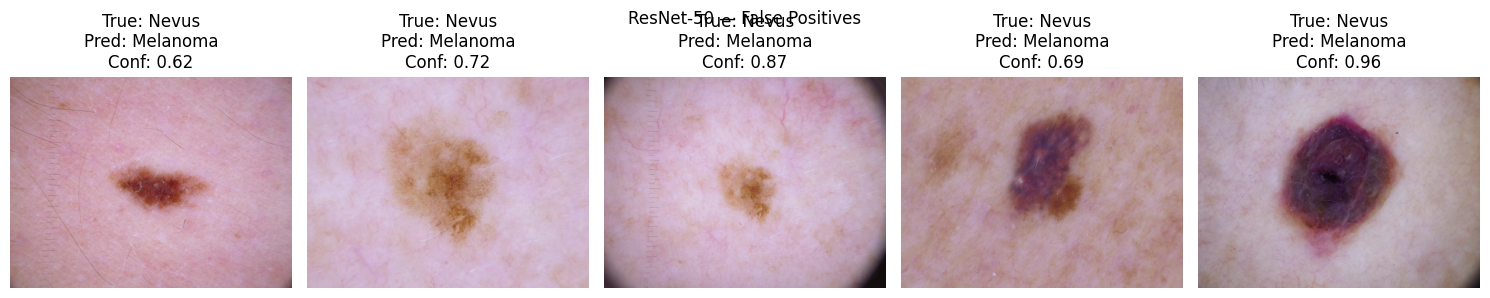

In [137]:
show_errors(
    test_df,
    resnet_fp_mask,
    y_true_resnet,
    y_pred_resnet,
    y_prob_resnet,
    "ResNet-50 — False Positives",
    n=5
)

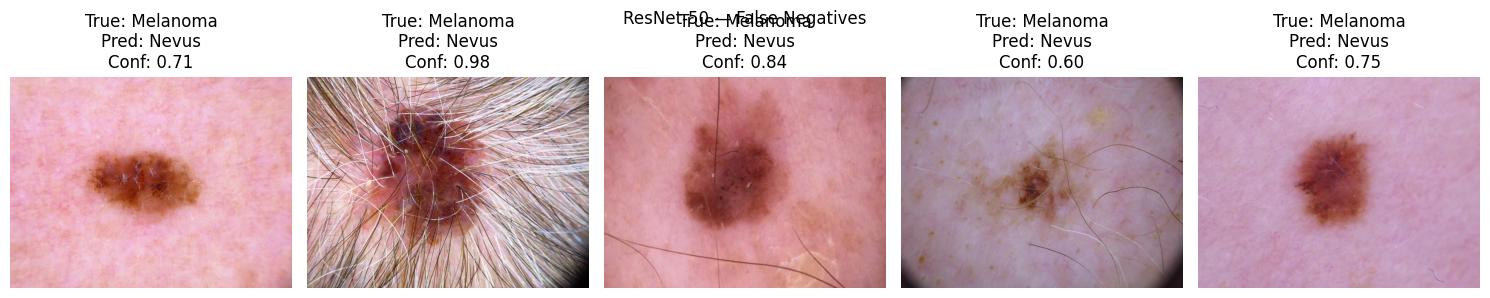

In [138]:
show_errors(
    test_df,
    resnet_fn_mask,
    y_true_resnet,
    y_pred_resnet,
    y_prob_resnet,
    "ResNet-50 — False Negatives",
    n=5
)

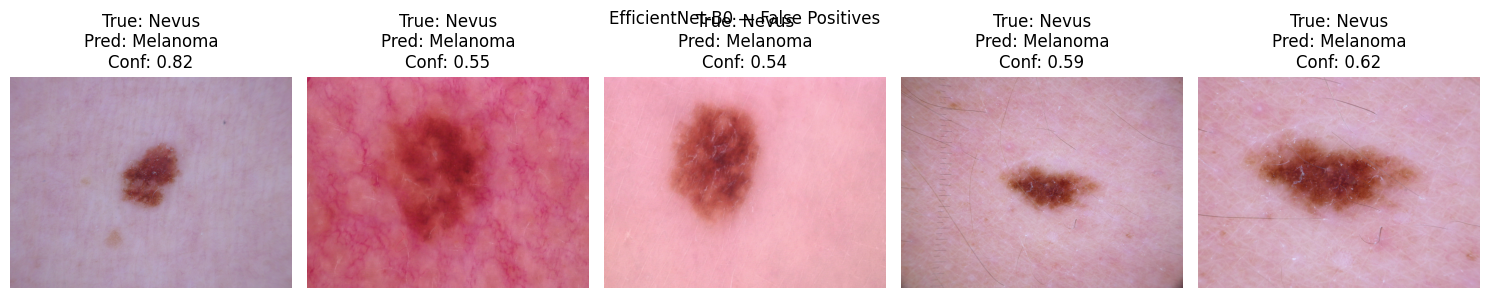

In [139]:
show_errors(
    test_df,
    eff_fp_mask,
    y_true_eff,
    y_pred_eff,
    y_prob_eff,
    "EfficientNet-B0 — False Positives",
    n=5
)

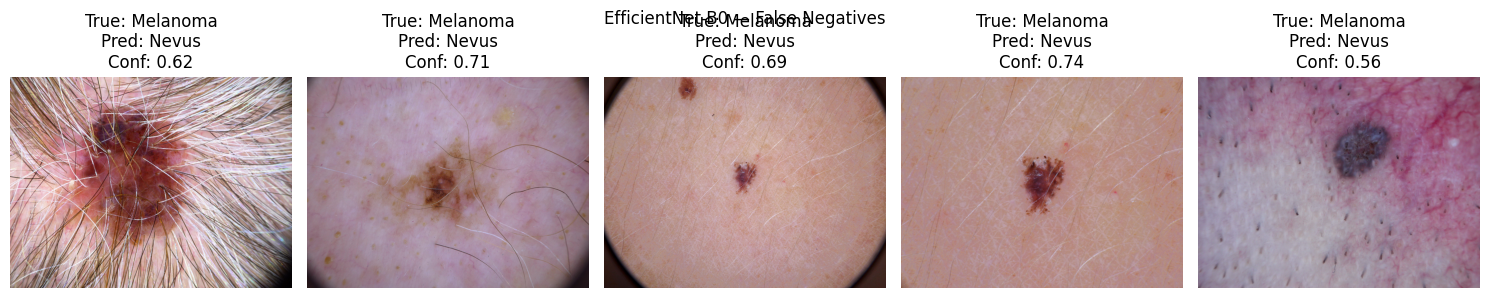

In [140]:
show_errors(
    test_df,
    eff_fn_mask,
    y_true_eff,
    y_pred_eff,
    y_prob_eff,
    "EfficientNet-B0 — False Negatives",
    n=5
)

## Correct Prediction Examples

In [142]:
def show_correct_predictions(
    df,
    y_true,
    y_pred,
    y_prob,
    title,
    n=5
):
    # Find correctly classified samples
    correct_mask = (y_true == y_pred)
    correct_indices = np.where(correct_mask)[0]

    # Take first n correct predictions
    selected_indices = correct_indices[:n]

    plt.figure(figsize=(15, 3))

    for plot_idx, idx in enumerate(selected_indices):

        image_path = df.iloc[idx]["image_path"]
        image = Image.open(image_path).convert("RGB")

        true_label = "Melanoma" if y_true[idx] == 1 else "Nevus"
        pred_label = "Melanoma" if y_pred[idx] == 1 else "Nevus"

        # Confidence of predicted class
        confidence = (
            y_prob[idx]
            if y_pred[idx] == 1
            else 1 - y_prob[idx]
        )

        plt.subplot(1, n, plot_idx + 1)
        plt.imshow(image)
        plt.axis("off")

        plt.title(
            f"True: {true_label}\n"
            f"Pred: {pred_label}\n"
            f"Conf: {confidence:.2f}"
        )

    plt.suptitle(title)
    plt.tight_layout()
    plt.show()

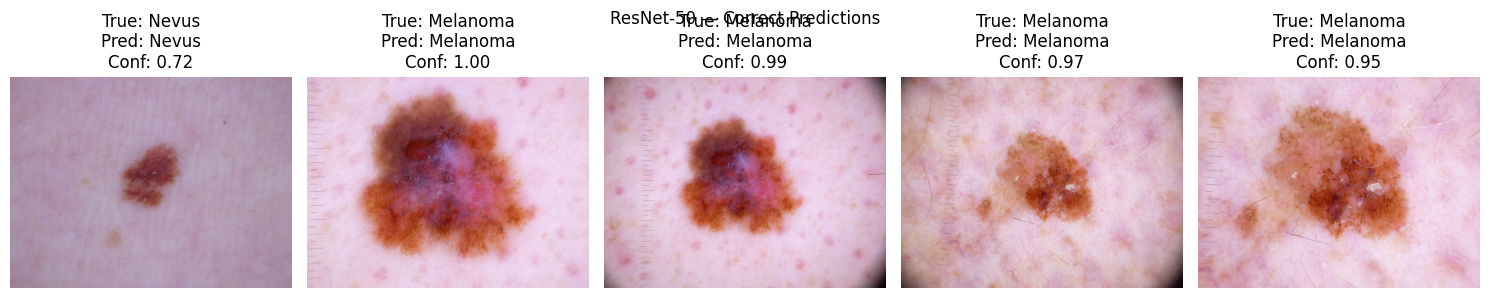

In [143]:
show_correct_predictions(
    test_df,
    y_true_resnet,
    y_pred_resnet,
    y_prob_resnet,
    "ResNet-50 — Correct Predictions",
    n=5
)

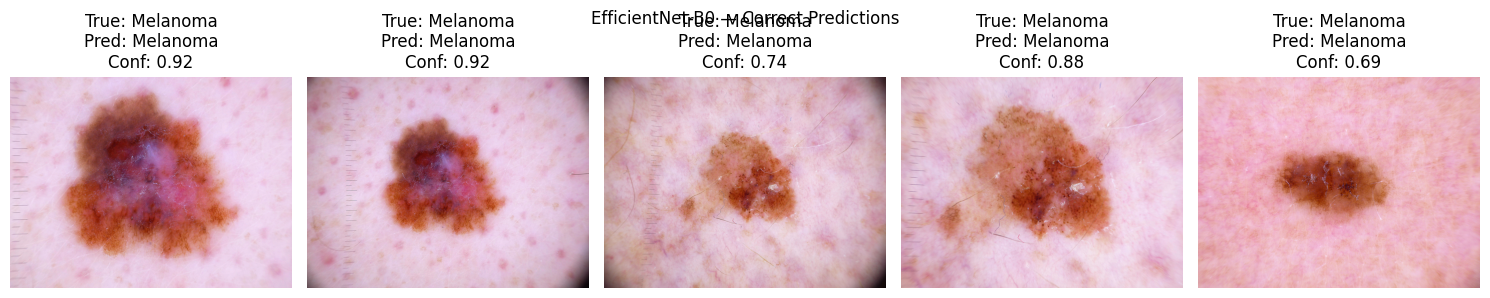

In [144]:
show_correct_predictions(
    test_df,
    y_true_eff,
    y_pred_eff,
    y_prob_eff,
    "EfficientNet-B0 — Correct Predictions",
    n=5
)

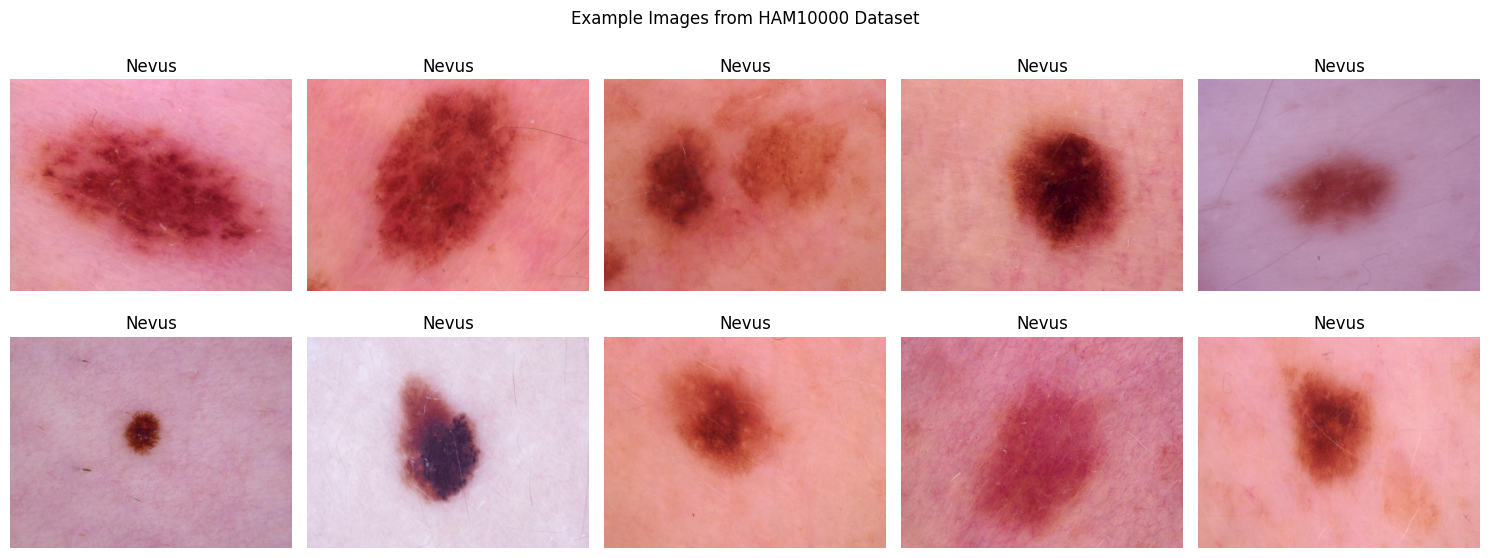

In [145]:
# Show example images from the dataset
fig, axes = plt.subplots(2, 5, figsize=(15, 6))

sample_df = df.sample(10, random_state=SEED).reset_index(drop=True)

for i, ax in enumerate(axes.flat):
    image_path = sample_df.loc[i, "image_path"]
    image = Image.open(image_path).convert("RGB")

    label = sample_df.loc[i, "dx"]

    ax.imshow(image)
    ax.set_title(
        "Melanoma" if label == "mel" else "Nevus"
    )
    ax.axis("off")

plt.suptitle("Example Images from HAM10000 Dataset")
plt.tight_layout()

plt.savefig(
    "dataset_example_images.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [156]:
# ==========================================
# Bonus – Grad-CAM Explainability Analysis
# ==========================================

print(resnet)

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 

## Bonus – Grad-CAM Explainability Analysis


In [157]:
# Install Grad-CAM library
!pip install -q grad-cam

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 53.8 MB/s eta 0:00:0000:0100:01
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [158]:
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image

print("✅ Grad-CAM imported successfully!")

✅ Grad-CAM imported successfully!


In [159]:
# Select the target layer for Grad-CAM
target_layers = [resnet.layer4]

print("Grad-CAM target layer:")
print(target_layers[0])

Grad-CAM target layer:
Sequential(
  (0): Bottleneck(
    (conv1): Conv2d(1024, 512, kernel_size=(1, 1), stride=(1, 1), bias=False)
    (bn1): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (conv2): Conv2d(512, 512, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
    (bn2): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (conv3): Conv2d(512, 2048, kernel_size=(1, 1), stride=(1, 1), bias=False)
    (bn3): BatchNorm2d(2048, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (relu): ReLU(inplace=True)
    (downsample): Sequential(
      (0): Conv2d(1024, 2048, kernel_size=(1, 1), stride=(2, 2), bias=False)
      (1): BatchNorm2d(2048, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
  )
  (1): Bottleneck(
    (conv1): Conv2d(2048, 512, kernel_size=(1, 1), stride=(1, 1), bias=False)
    (bn1): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, track_running_st

In [160]:
# Create Grad-CAM object
cam = GradCAM(
    model=resnet,
    target_layers=target_layers
)

print("✅ Grad-CAM object created successfully!")

✅ Grad-CAM object created successfully!


In [161]:
# Get one batch from the test loader
images, labels = next(iter(test_loader))

# Select the first image
input_tensor = images[0].unsqueeze(0).to(DEVICE)

# True label
true_label = labels[0].item()

# Get model prediction
resnet.eval()

with torch.no_grad():
    output = resnet(input_tensor)
    prediction = torch.argmax(output, dim=1).item()
    probabilities = torch.softmax(output, dim=1)

print("True label:", "Melanoma" if true_label == 1 else "Nevus")
print("Predicted label:", "Melanoma" if prediction == 1 else "Nevus")
print("Melanoma probability:", f"{probabilities[0, 1].item():.4f}")

True label: Nevus
Predicted label: Nevus
Melanoma probability: 0.2763


In [162]:
# Generate Grad-CAM heatmap

targets = [ClassifierOutputTarget(prediction)]

grayscale_cam = cam(
    input_tensor=input_tensor,
    targets=targets
)

grayscale_cam = grayscale_cam[0]

print("Grad-CAM heatmap shape:", grayscale_cam.shape)

Grad-CAM heatmap shape: (224, 224)


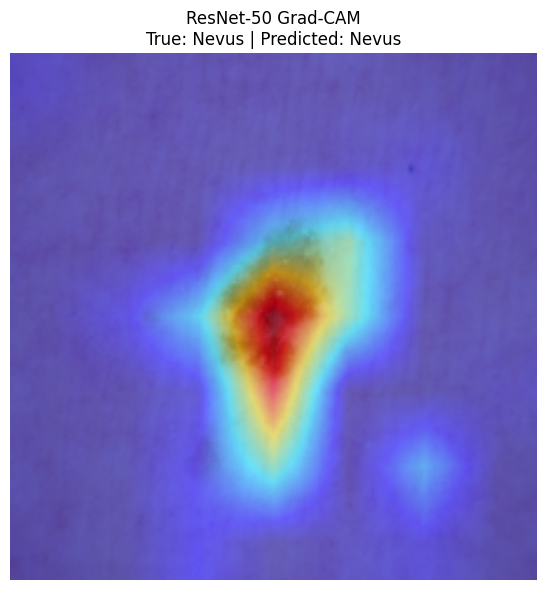

In [163]:
# Prepare the original image for Grad-CAM visualization

image_np = images[0].permute(1, 2, 0).cpu().numpy()

# Normalize image for visualization
image_np = image_np - image_np.min()
image_np = image_np / image_np.max()

# Create Grad-CAM visualization
visualization = show_cam_on_image(
    image_np.astype(np.float32),
    grayscale_cam,
    use_rgb=True
)

plt.figure(figsize=(6, 6))
plt.imshow(visualization)
plt.axis("off")

plt.title(
    f"ResNet-50 Grad-CAM\n"
    f"True: {'Melanoma' if true_label == 1 else 'Nevus'} | "
    f"Predicted: {'Melanoma' if prediction == 1 else 'Nevus'}"
)

plt.tight_layout()
plt.show()

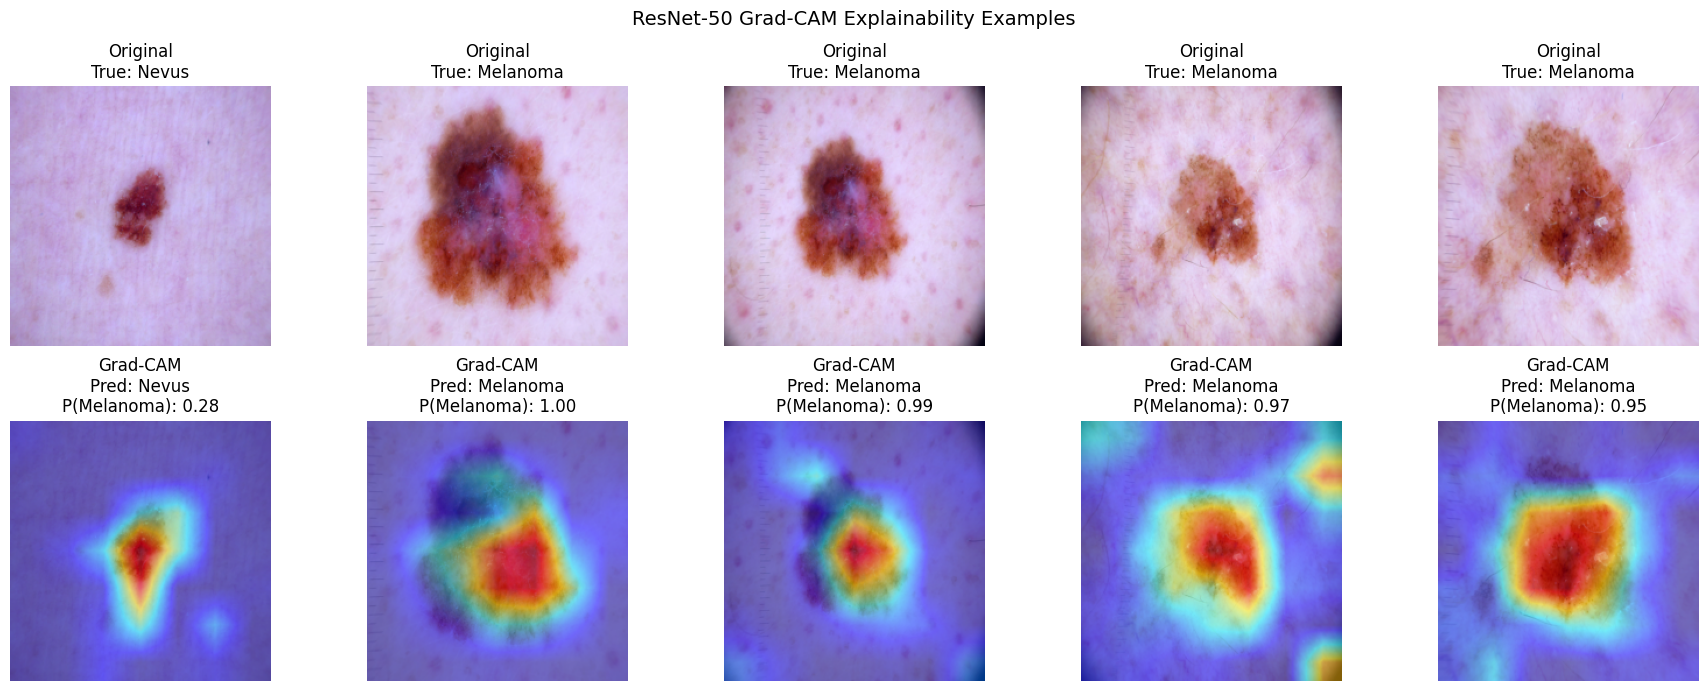

In [164]:
# Generate Grad-CAM visualizations for 5 test images

resnet.eval()

# Select 5 images from the test set
sample_indices = [0, 1, 2, 3, 4]

fig, axes = plt.subplots(2, 5, figsize=(18, 7))

for col, idx in enumerate(sample_indices):

    # Get image and label
    image_tensor = test_loader.dataset[idx][0]
    true_label = test_loader.dataset[idx][1]

    input_tensor = image_tensor.unsqueeze(0).to(DEVICE)

    # Model prediction
    with torch.no_grad():
        output = resnet(input_tensor)
        prediction = torch.argmax(output, dim=1).item()
        probability = torch.softmax(output, dim=1)[0, 1].item()

    # Grad-CAM
    targets = [ClassifierOutputTarget(prediction)]

    grayscale_cam = cam(
        input_tensor=input_tensor,
        targets=targets
    )[0]

    # Prepare image for visualization
    image_np = image_tensor.permute(1, 2, 0).cpu().numpy()

    image_np = image_np - image_np.min()
    image_np = image_np / image_np.max()

    visualization = show_cam_on_image(
        image_np.astype(np.float32),
        grayscale_cam,
        use_rgb=True
    )

    # Original image
    axes[0, col].imshow(image_np)
    axes[0, col].axis("off")
    axes[0, col].set_title(
        f"Original\n"
        f"True: {'Melanoma' if true_label == 1 else 'Nevus'}"
    )

    # Grad-CAM
    axes[1, col].imshow(visualization)
    axes[1, col].axis("off")
    axes[1, col].set_title(
        f"Grad-CAM\n"
        f"Pred: {'Melanoma' if prediction == 1 else 'Nevus'}\n"
        f"P(Melanoma): {probability:.2f}"
    )

plt.suptitle(
    "ResNet-50 Grad-CAM Explainability Examples",
    fontsize=14
)

plt.tight_layout()

plt.savefig(
    "resnet_gradcam_examples.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()